# Seaborn

## Введение в seaborn

In [2]:
import seaborn as sns

Установка общей темы оформления для всех графиков. Один вызов — и все последующие графики (и Seaborn, и Matplotlib) будут рисоваться в едином стиле: цвета, шрифты, сетка, отступы, размеры линий (логично настраивает внутри скобок, смотреть по надобности):

In [4]:
sns.set_theme()

- `data` - те данные что хотим отобразить. Обычно DataFrame
- `x, y` - столбцы по каждой оси
- `col` - группировка: разбивает один график на несколько, при этом и данные разбиваются
- `hue` - разделяет данные, задавая кажому уникальному значению свой цвет
- `style` - тоже разделяет данные по уникальному значению, но теперь по форме
- `size` - и снова разделяет данные по уникальному значению, но теперь по размеру

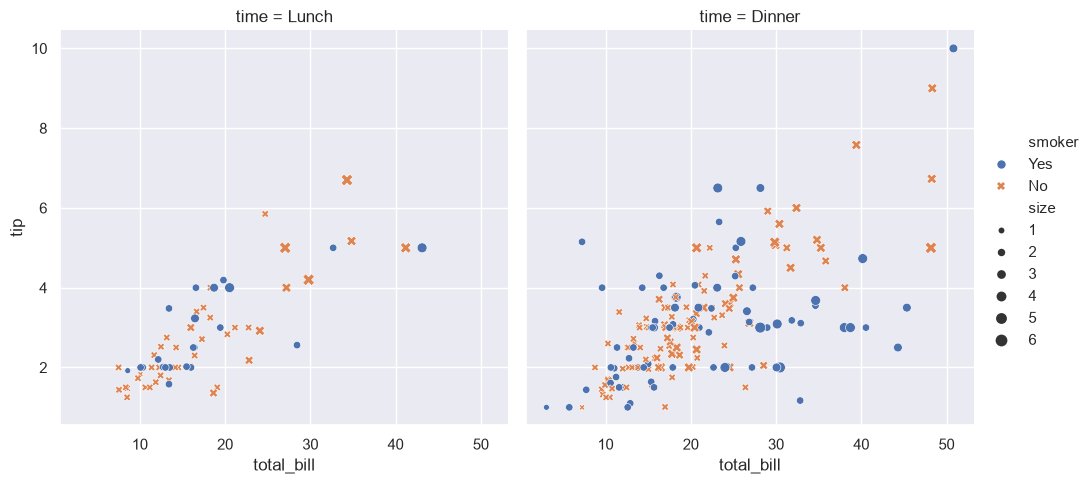

In [7]:
tips = sns.load_dataset("tips")   # Просто игрушечные данные предоставленные самим Seaborn

_ = sns.relplot(
    data=tips,
    x="total_bill", y="tip", col="time",
    hue="smoker", style="smoker", size="size",
)

## Высокоуровневый API для статистической графики

Тут добавляется параметр `facet_kws`. Он отвечает за структуру сетки (оси, размеры, рамки). В данном случаи мы позволили двум разным графикам подстроиться под свою ось x, а не общую:

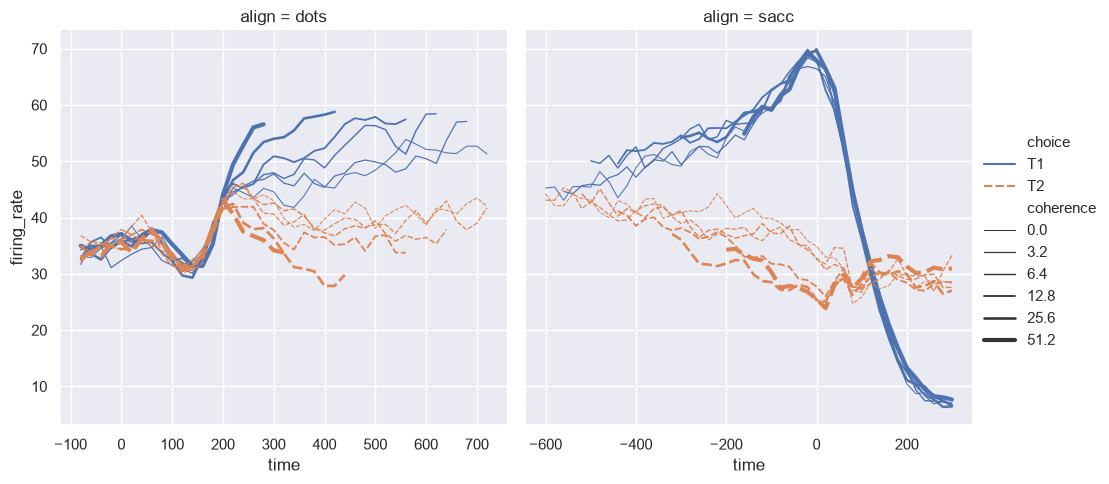

In [10]:
dots = sns.load_dataset("dots")
_ = sns.relplot(
    data=dots, kind="line",
    x="time", y="firing_rate", col="align",
    hue="choice", size="coherence", style="choice",
    facet_kws=dict(sharex=False)
)

`kind` меняет тип графика, в данным случаи поменяли на линейный график:

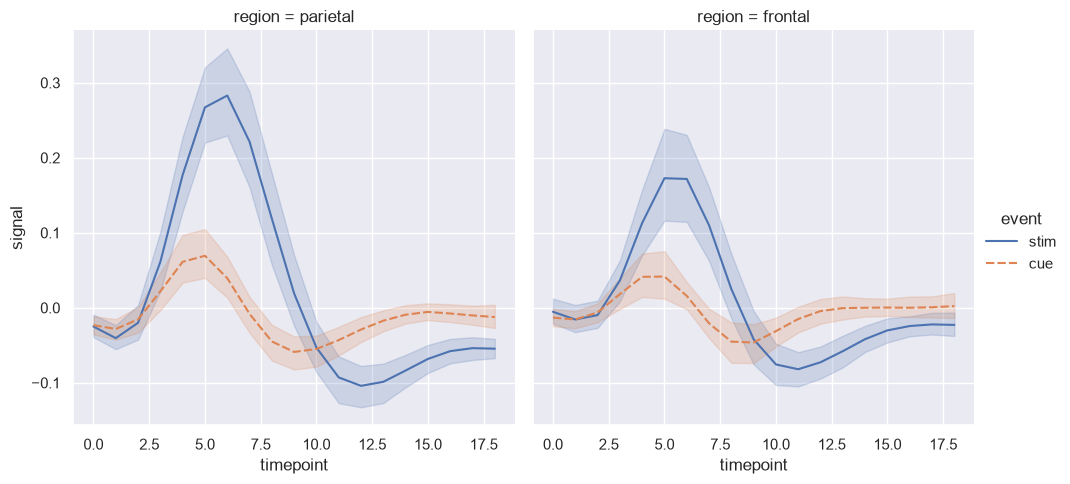

In [11]:
fmri = sns.load_dataset("fmri")
_ = sns.relplot(
    data=fmri, kind="line",
    x="timepoint", y="signal", col="region",
    hue="event", style="event",
)

`sns.lmplot()` - график регрессии. По сути это обычный точечный график, но он автоматически строит линию регрессии. Это прямая линия, которая лучше всего описывает зависимость $y$ от $x$. Строится методом наименьших квадратов. Область вокруг линии — доверительный интервал (насколько мы уверены, что истинная зависимость проходит именно здесь):

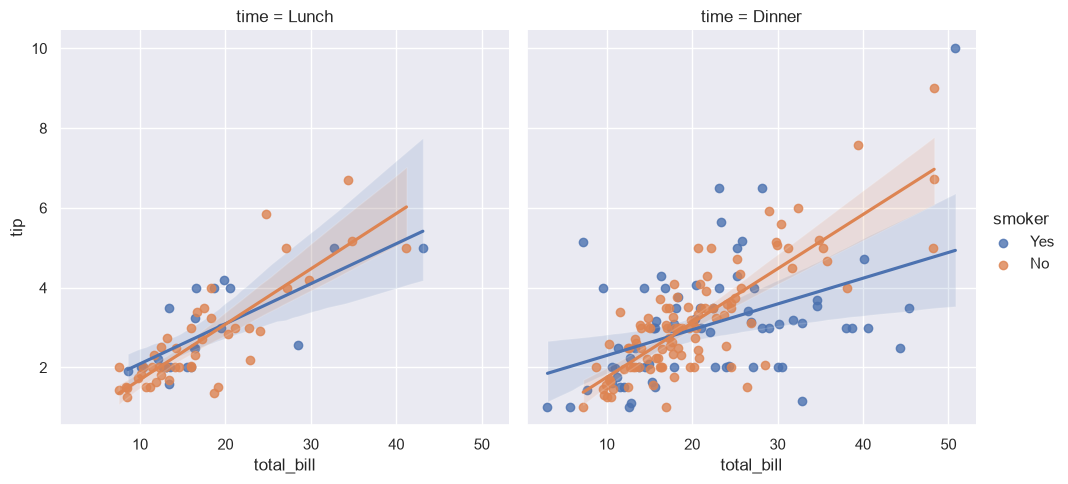

In [12]:
_ = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", hue="smoker")

`sns.displot()` - столбчатый график, `kde` - это ядерная оценка плотности. Она показывает распределение, сводя площадь под графиком к единице:

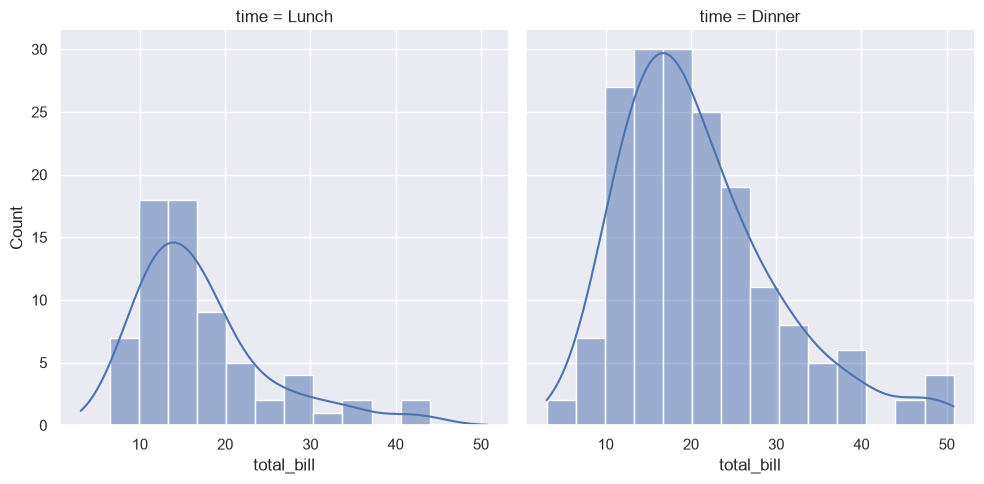

In [17]:
_ = sns.displot(data=tips, x="total_bill", col="time", kde=True)

Если мы хотим увидеть по оси $y$ именно плотность вероятности, а не количество, то можем написать `stat='density'`:

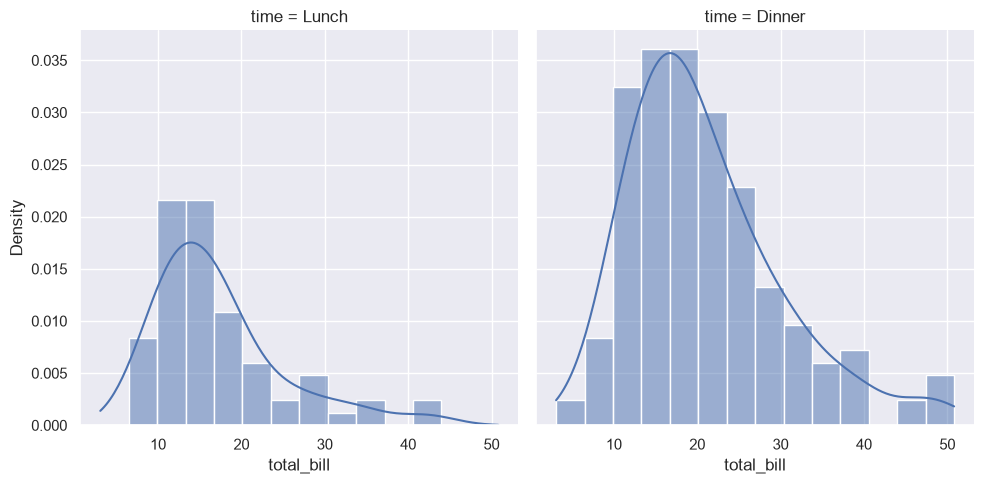

In [22]:
_ = sns.displot(data=tips, x='total_bill', col="time", kde=True, stat='density')

Это всё тот же столбчатый график, но через накопленную сумму, тут параметры следующие:
- `kind="ecdf"` - как раз и делает график накопленной суммы из столбчатого
- `rug=True` - добавляет риски снизу. Они показывают где находится каждое значение по оси $x$ (это как опущенные вниз точки точечного графика)

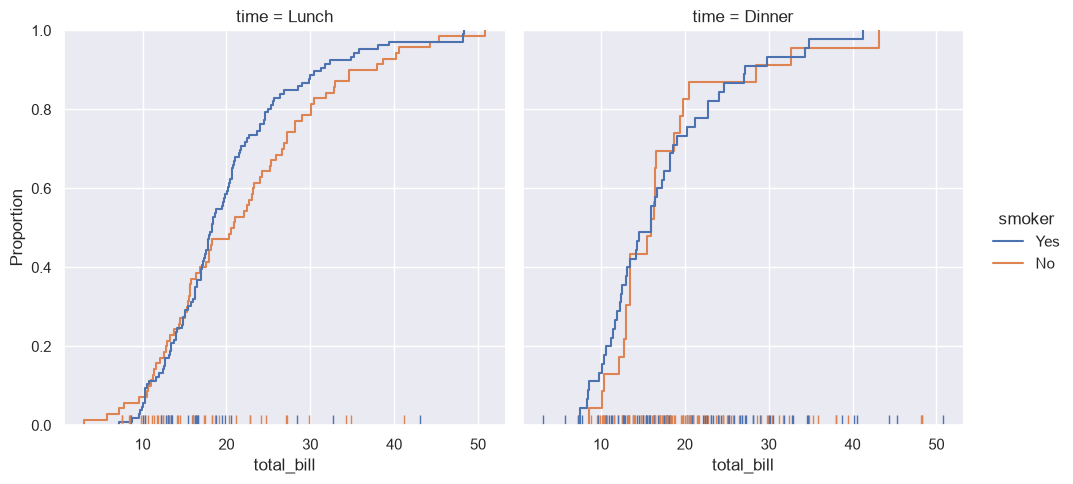

In [20]:
_ = sns.displot(data=tips, kind="ecdf", x="total_bill", col="time", hue="smoker", rug=True)

### Графики для категориальных данных

- `kind="swarm"` - в данном случаи просто запрещает точкам накладываться друг на друга

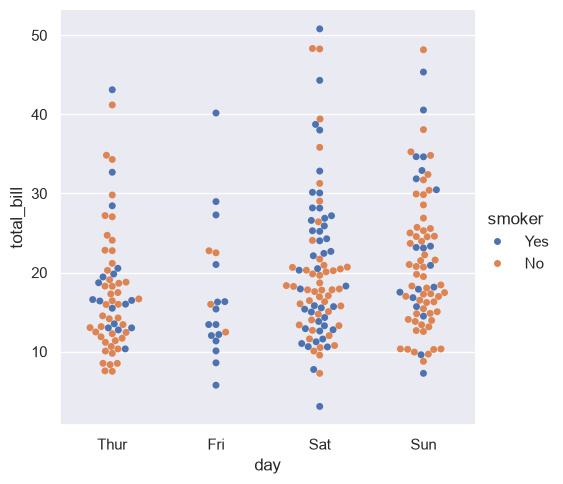

In [28]:
_ = sns.catplot(data=tips, kind="swarm", x="day", y="total_bill", hue="smoker")

- `kind="violin"` - график "Скрипка". Одна из разновидностей boxplot. В классической форме для каждого `hue` он свой, но благодаря параметру `split=True` они совмещаются (слева и справа)

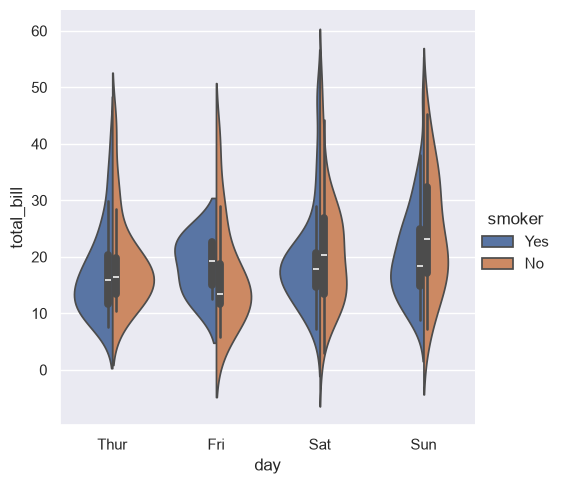

In [29]:
_ = sns.catplot(data=tips, kind="violin", x="day", y="total_bill", hue="smoker", split=True)

Классический столбчатый график:

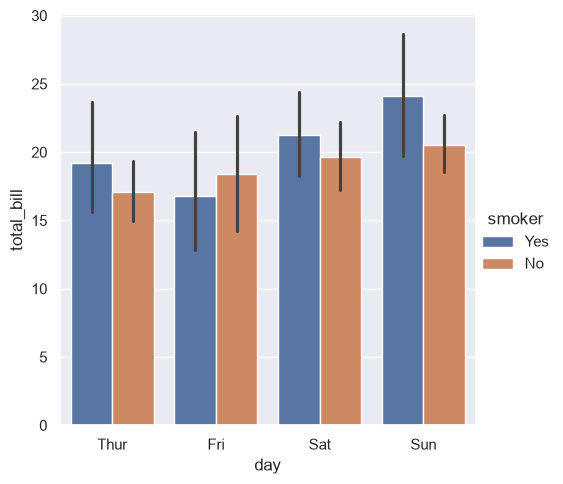

In [32]:
_ = sns.catplot(data=tips, kind="bar", x="day", y="total_bill", hue="smoker")

## Многомерные представления сложных наборов данных 

Обычный точечный график, где сверху и справа дополнительные гистограммы:

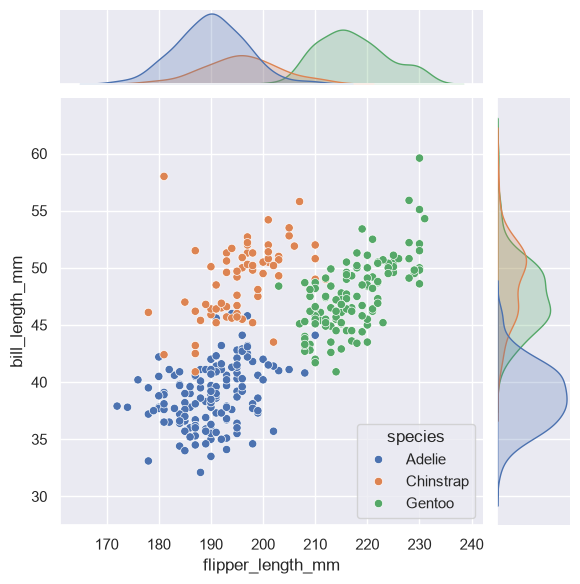

In [34]:
penguins = sns.load_dataset("penguins")
_ = sns.jointplot(data=penguins, x="flipper_length_mm", y="bill_length_mm", hue="species")

Развёрнутый большой график:

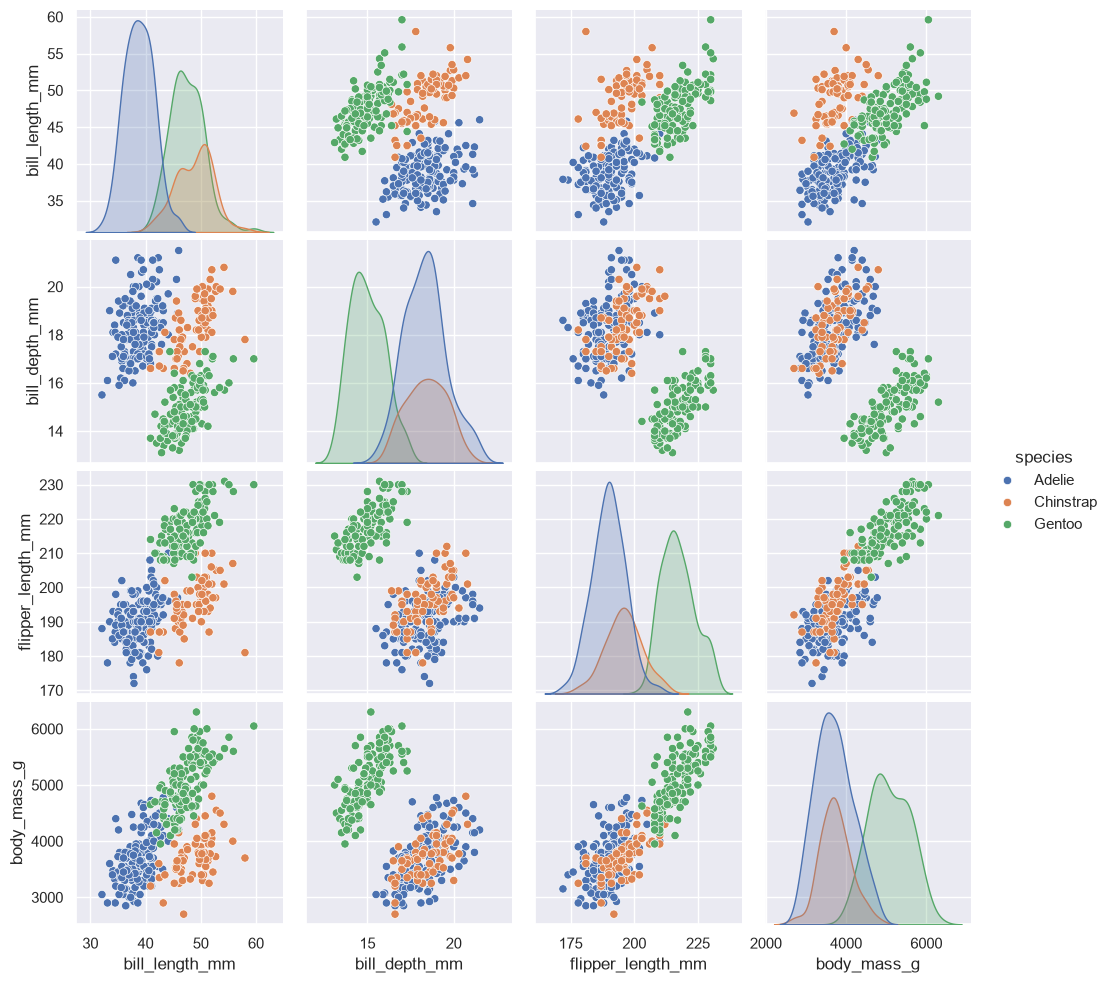

In [35]:
_ = sns.pairplot(data=penguins, hue="species")

Мы можем более гибко настраивать графики через переменную.

- `corner=True` - убирает область под графики справа сверху

- `g.map_lower()` - заполняет всю область под диагональю
    - `sns.kdeplot` - вместо точек круги
        - `hue=None` - убирает цветовое разделение конкретно для этого графика
        - `levels=5` - количество колец
- `g.map_diag()` - логично, что заполняет диагональ
    - `sns.histplot`
        - `element="step"` - по умолчанию обводка будет белой, а так она совпадает с цветом столбцов
        - `linewidth=1` - толщина обводки, может быть и 0

- `g.add_legend()` - добавляет легенду, где:
    - `frameon=True` - обводка легенды
    - `bbox_to_anchor=(.61, .6)` - положение легенды (в примере он просто добавился отдельно, но можно и сразу указывать)

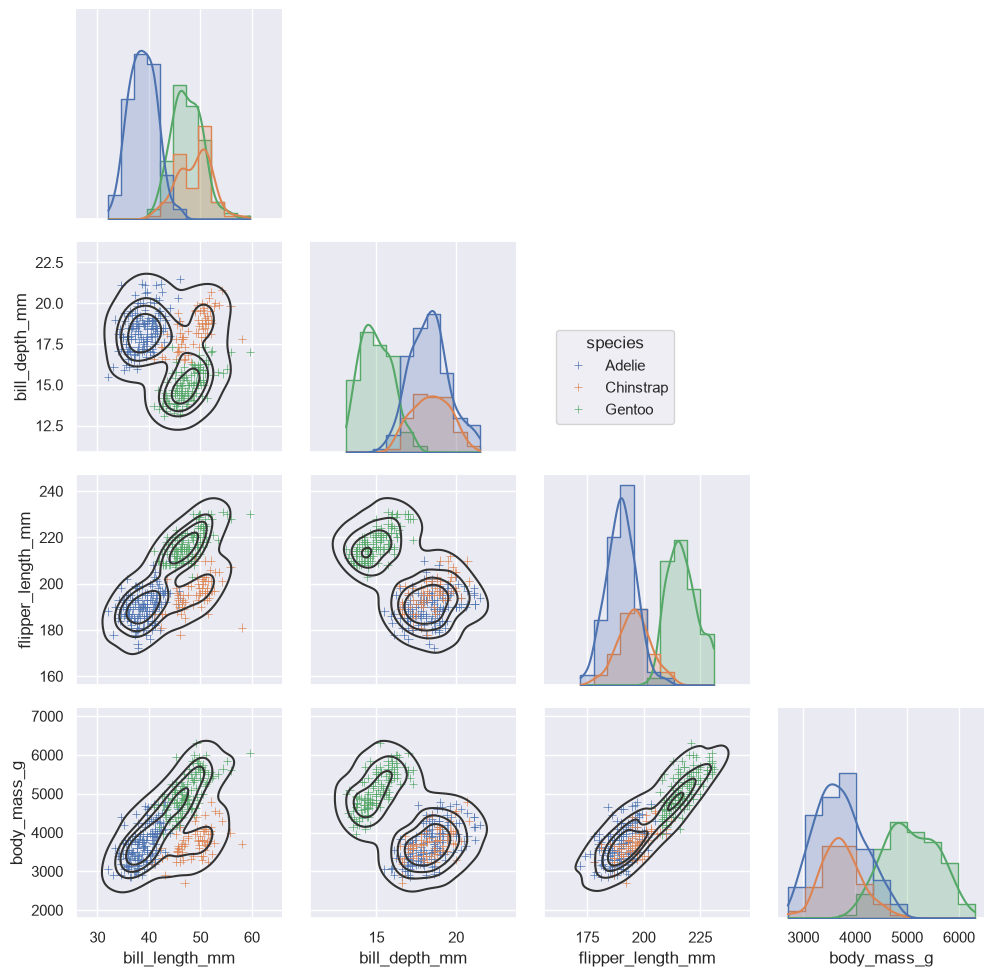

In [50]:
g = sns.PairGrid(penguins, hue="species", corner=True)
g.map_lower(sns.kdeplot, hue=None, levels=5, color=".2")
g.map_lower(sns.scatterplot, marker="+")
g.map_diag(sns.histplot, element="step", linewidth=1, kde=True)
g.add_legend(frameon=True)
g.legend.set_bbox_to_anchor((.61, .6))

## Настроенные по умолчанию параметры и гибкая настройка

- `sns.set_theme(style="ticks", font_scale=1.25)`:
    - `style="ticks"` - убирает фон за графиком
    - `font_scale=1.25` - размер текста

- `sns.relplot()`:
    - `palette="crest"` - меняет палитру раскраски точек
    - `s=100` - размер точек

- `labelpad=10` - насколько близко подписи к графику
- `g.figure.set_size_inches(6.5, 4.5)` - размер всего графика
- `g.ax.margins(.15)` - "это как поля на странице книги. Текст не начинается вплотную к краю листа — есть отступы, чтобы было удобно читать"
- `g.despine(trim=True)` - убирает верхнюю и правую рамки графика и обрезает оставшиеся рамки (левую и нижнюю. Линии оси $x$ и $y$) по данным. То есть делает график визуально чище и аккуратнее

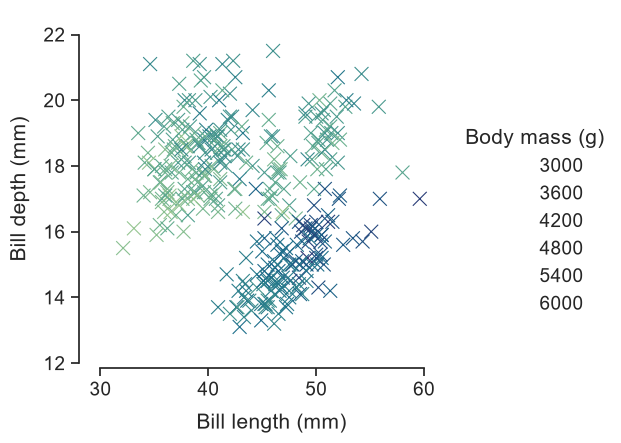

In [71]:
sns.set_theme(style="ticks", font_scale=1.25)
g = sns.relplot(
    data=penguins,
    x="bill_length_mm", y="bill_depth_mm", hue="body_mass_g",
    palette="crest", marker="x", s=100,
)
g.set_axis_labels("Bill length (mm)", "Bill depth (mm)", labelpad=10)
g.legend.set_title("Body mass (g)")
g.figure.set_size_inches(6.5, 4.5)
g.ax.margins(.15)
g.despine(trim=True)